# Lab 7 - go-to-goal: 57

The controller drives through 9 goal points using nonlinear go-to-goal control.

**log format:** headerless `x_cm,y_cm,time_ms`

In [1]:
from pathlib import Path
from zipfile import ZipFile
import hashlib
import json
import re
import shutil
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown

ROOT = Path.cwd()
if (ROOT / 'Labs/Lab-7/report.ipynb').exists():
    ROOT = ROOT / 'Labs/Lab-7'
OUTPUT = ROOT / 'nvm/report_outputs'
OUTPUT.mkdir(parents=True, exist_ok=True)

# Local defaults. In Colab, upload the files with their existing names, or edit these.
SIM_FILE = 'log/sim_odometry_data_57.txt'
REAL_FILE = 'log/real_odometry_data_57.txt'
# from google.colab import files
# uploaded = files.upload()

plt.rcParams.update({'font.size': 10, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})

def show_table(frame):
    rounded = frame.round(3)
    display(rounded)

## Controller, odometry and planned coordinates

For distance (d) in metres and error (e) in radians:

\[
e=\operatorname{wrap}(\operatorname{atan2}(y_g-y,x_g-x)-\theta),\qquad
v=K_d d\cos(e),\qquad
\omega=K_\mathrm{angle}e+K_d\sin(e)\cos(e).
\]

The program limits requested linear/angular velocity and wheel power by scaling
each command pair together. Wheel commands use `vL=v-W*omega/2`,
`vR=v+W*omega/2` and `power=wheel_velocity/(r*motor_gain)`.
There is no friction compensation or separate wheel-speed PI in this version.

Odometry uses startup-relative encoder angles, cumulative signed centre travel
`S=(encL+encR)*r/2`, `dS=S-oldS`, continuous heading
`theta=(encR-encL)*r/W`, and midpoint-heading translation. Only the goal error
is wrapped. A waypoint is accepted inside the programmed distance threshold.

The table below reads the **current saved QRS settings** when available. In
Colab without QRS files, it uses the embedded snapshot. These settings must match
the actual settings used to collect the logs: a three-column log does not encode
its controller gains. Match path, gains and tolerance between runs; robot geometry
is platform-specific. Use the same initial pose and coordinate convention.

In [2]:
# Snapshot from the saved programs when this report was prepared.
PROGRAM_SNAPSHOT = {
    'sim': {'K_d': 0.8, 'K_angle': 20.0, 'threshold': 0.015,
            'r': 0.028, 'W': 0.154, 'motor_gain': 0.1,
            'v_max': 0.12, 'omega_max': 1.5, 'max_power': 60.0, 'period_ms': 20},
    'real': {'K_d': 0.8, 'K_angle': 20.0, 'threshold': 0.015,
             'r': 0.042, 'W': 0.194, 'motor_gain': 0.1,
             'v_max': 0.12, 'omega_max': 1.5, 'max_power': 60.0, 'period_ms': 20},
}
WP = np.array([[0, 0], [40, 0], [40, 40], [0, 40], [0, 80],
               [40, 80], [60, 80], [100, 80], [60, 40], [60, 0]], dtype=float)

def program_settings(path, fallback):
    result = dict(fallback)
    source = 'embedded snapshot; verify against the run'
    points = WP.copy()
    if path.exists():
        with ZipFile(path) as archive:
            for name in archive.namelist():
                if '/logical/' not in name or '/Function/' not in name or name.endswith('/'):
                    continue
                raw = re.sub(r'(<\/?)qReal::Id', r'\1qReal_Id', archive.read(name).decode('utf-8'))
                props = {p.get('key'): p.get('value', '')
                         for p in ET.fromstring(raw).findall('properties/*')}
                body = props.get('Body', '')
                if 'x_target =' not in body or 'y_target =' not in body:
                    continue
                body = '\n'.join(line.split('--', 1)[0] for line in body.splitlines())
                number = r'[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?'
                values = {k: float(v) for k, v in re.findall(r'\b(\w+)\s*=\s*(' + number + r')\s*;', body)}
                if 'K_dist' in values:
                    values['K_d'] = values['K_dist']
                result.update({k: values[k] for k in result if k in values})
                axes = [re.search(axis + r'_target\s*=\s*\{([^}]*)\}', body).group(1)
                        for axis in ['x', 'y']]
                goals = np.column_stack([[float(v.strip()) for v in axis.split(',')] for axis in axes])
                points = np.vstack([[0, 0], goals * 100])
                source = str(path.relative_to(ROOT)) + ' (current saved settings; verify against the run)'
                break
    return result, points, source

parameters, settings_sources = {}, {}
for name in ['sim', 'real']:
    parameters[name], points, settings_sources[name] = program_settings(
        ROOT / f'go_to_goal_{name}.qrs', PROGRAM_SNAPSHOT[name])
    if not np.array_equal(points, WP):
        raise ValueError(f'{name}: saved program waypoints differ from this report; update WP and collect matched runs.')

GOALS = WP[1:]
EPS_CM = parameters['sim']['threshold'] * 100
shared = ['K_d', 'K_angle', 'threshold', 'v_max', 'omega_max', 'max_power', 'period_ms']
mismatches = [key for key in shared if parameters['sim'][key] != parameters['real'][key]]
if mismatches:
    raise ValueError('Unmatched settings: ' + ', '.join(mismatches))
print('Shared controller settings match.')
for name, source in settings_sources.items():
    print(f'{name}: {source}')
parameter_table = pd.DataFrame({
    name: {'K_d (1/s)': p['K_d'], 'K_angle (1/s)': p['K_angle'],
           'Acceptance radius (cm)': p['threshold'] * 100,
           'Requested wait (ms)': p['period_ms'], 'v_max (m/s)': p['v_max'],
           'omega_max (rad/s)': p['omega_max'], 'Maximum power (%)': p['max_power'],
           'Wheel radius r (cm)': p['r'] * 100, 'Wheel spacing W (cm)': p['W'] * 100,
           'Motor gain (rad/s per %)': p['motor_gain']}
    for name, p in parameters.items()
})
show_table(parameter_table)

Shared controller settings match.
sim: go_to_goal_sim.qrs (current saved settings; verify against the run)
real: go_to_goal_real.qrs (current saved settings; verify against the run)


,sim,real
K_d (1/s),0.80,0.80
K_angle (1/s),20.00,20.00
Acceptance radius (cm),1.50,1.50
Requested wait (ms),20.00,20.00
v_max (m/s),0.12,0.12
omega_max (rad/s),1.50,1.50
Maximum power (%),60.00,60.00
Wheel radius r (cm),2.80,4.20
Wheel spacing W (cm),15.40,19.40
Motor gain (rad/s per %),0.10,0.10


## Input files

The report uses `log/sim_odometry_data_57.txt` and
`log/real_odometry_data_57.txt`, each containing headerless `x_cm,y_cm,time_ms`.
The table records the selected paths, sample counts and hashes.
The loader checks three finite numeric columns and nondecreasing timestamps;
invalid runs raise an error rather than filling or dropping bad samples.


In [3]:
def resolve_input(requested, kind):
    candidates = [ROOT / requested, ROOT / Path(requested).name,
                  ROOT / f'odometry_data_{kind}.txt']
    return next((p for p in candidates if p.is_file()), candidates[0])

def load_log(path):
    text = path.read_text(encoding='utf-8-sig')
    lines = [line for line in text.splitlines() if line.strip()]
    if lines and all(line.strip().lower() == 'nan' for line in lines):
        raise ValueError(f'{len(lines)} NaN-only lines: logging/export failed; collect a corrected run.')
    if not lines:
        raise ValueError('The log is empty.')
    try:
        data = np.loadtxt(path, delimiter=',', ndmin=2, encoding='utf-8-sig')
    except ValueError as error:
        raise ValueError('Expected headerless x_cm,y_cm,time_ms rows: ' + str(error)) from error
    if data.shape[1] != 3 or len(data) < 2:
        raise ValueError(f'Expected at least two rows and three columns; got {data.shape}.')
    if not np.isfinite(data).all():
        row, col = np.argwhere(~np.isfinite(data))[0]
        raise ValueError(f'Nonfinite value at sample {row+1}, column {col+1}; recollect rather than fill values.')
    if (data[:, 2] < 0).any() or (np.diff(data[:, 2]) < 0).any():
        raise ValueError('Timestamps must be nonnegative and nondecreasing; check for appended runs.')
    if data[-1, 2] <= data[0, 2]:
        raise ValueError('Logged time never advances.')
    return data

def read_runs(files):
    loaded, information = {}, {}
    for kind, requested in files.items():
        path = resolve_input(requested, kind)
        info = {'path': str(path), 'status': 'missing', 'sha256': None, 'samples': None}
        if path.exists():
            info['sha256'] = hashlib.sha256(path.read_bytes()).hexdigest()
            try:
                loaded[kind] = load_log(path)
                info.update(status='valid', samples=len(loaded[kind]))
            except ValueError as error:
                info['status'] = 'INVALID: ' + str(error)
        information[kind] = info
    return loaded, information

runs, inputs = read_runs({'sim': SIM_FILE, 'real': REAL_FILE})
show_table(pd.DataFrame({kind: {'Selected file': info['path'], 'Status': info['status'],
                               'Samples': info['samples'], 'SHA-256': info['sha256']}
                         for kind, info in inputs.items()}))
if set(runs) != {'sim', 'real'}:
    raise ValueError('Both valid logs are required. Check the input table above.')

,sim,real
Selected file,C:\Users\yusup\Documents\GitHub\newuu\CS413\La...,C:\Users\yusup\Documents\GitHub\newuu\CS413\La...
Status,valid,valid
Samples,2562,637
SHA-256,2f95e4f336d385b46b8ea2a7701ccaf36a30970caaf6dd...,535d4411b3ccf7fe31ee93d9fa679dc22f53a84438dd09...


## Planned path versus recorded trajectories

Coordinates are in cm, with x along the initial heading and positive y to its
left. The plan and logs use the same frame; no reflection, spatial fitting,
rescaling or time alignment is applied. The grey transfer joins 5 to 7; its
linestyle does not claim that the robot lifted a pen. P8 is the bend of 7.
All recorded curves are **encoder odometry estimates**, not externally measured tracks.

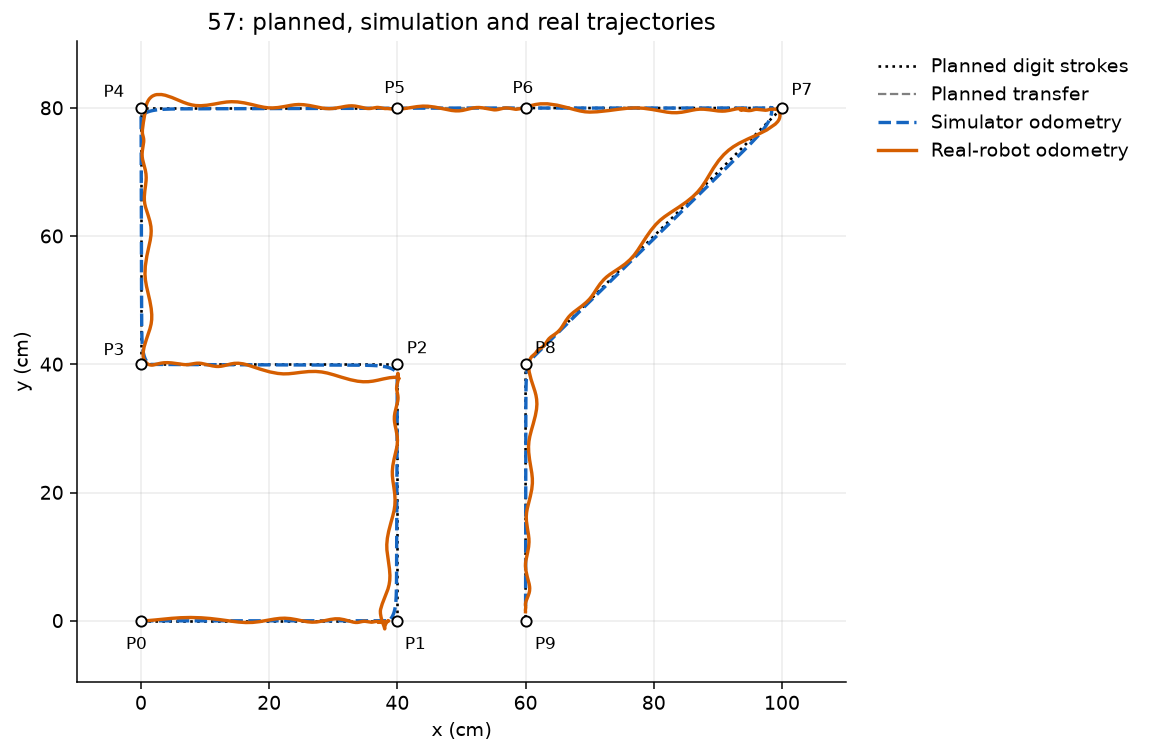

In [4]:
fig, ax = plt.subplots(figsize=(8.4, 6), layout='constrained')
ax.plot(WP[:6, 0], WP[:6, 1], 'k:', lw=1.4, label='Planned digit strokes')
ax.plot(WP[6:, 0], WP[6:, 1], 'k:', lw=1.4)
ax.plot(WP[5:7, 0], WP[5:7, 1], color='gray', ls='--', lw=1.2, label='Planned transfer')
ax.scatter(WP[:, 0], WP[:, 1], s=30, facecolors='white', edgecolors='black', zorder=4)
styles = {'sim': ('#1565c0', '--', 'Simulator odometry'),
          'real': ('#d55e00', '-', 'Real-robot odometry')}
for kind, data in runs.items():
    color, style, label = styles[kind]
    ax.plot(data[:, 0], data[:, 1], color=color, ls=style, lw=1.8, label=label)
offsets = [(-8, -15), (4, -15), (5, 6), (-20, 5), (-20, 6),
           (-7, 8), (-7, 8), (5, 7), (5, 6), (5, -15)]
for i, ((x, y), offset) in enumerate(zip(WP, offsets)):
    ax.annotate(f'P{i}', (x, y), xytext=offset, textcoords='offset points', fontsize=9)
ax.set(xlabel='x (cm)', ylabel='y (cm)', title='57: planned, simulation and real trajectories')
ax.set_aspect('equal', adjustable='box')
ax.margins(0.1)
ax.grid(alpha=0.25)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
fig.savefig(OUTPUT / 'trajectory_comparison.png', dpi=170, bbox_inches='tight')
display(fig)
plt.close(fig)

## Waypoint-miss table and ordered arrival check

The required course metric is the **minimum sampled distance over the whole run**:
`miss(P) = min(hypot(x-Px, y-Py))`. A later stroke can pass closer to a waypoint
than its initial arrival, so a small global miss alone does not prove correct
ordering. The supporting check below scans samples in sequence using the
programmed acceptance radius. Final stopping samples are allowed after the last goal.
It infers arrivals from the three-column log; it does not observe the program's
target index or independently verify physical accuracy.

In [5]:
def waypoint_miss(data, waypoints=WP):
    return np.linalg.norm(data[:, None, :2] - waypoints[None, :, :], axis=2).min(axis=0)

def ordered_arrivals(data, goals=GOALS, tolerance_cm=EPS_CM):
    target, arrivals = 0, []
    for sample, row in enumerate(data):
        if target == len(goals):
            break
        distance = float(np.linalg.norm(row[:2] - goals[target]))
        if distance <= tolerance_cm + 1e-6:
            arrivals.append({'goal': target+1, 'sample': sample,
                             'time_ms': float(row[2]), 'distance_cm': distance})
            target += 1
    return arrivals

misses = {kind: waypoint_miss(data) for kind, data in runs.items()}
arrivals = {kind: ordered_arrivals(data, tolerance_cm=parameters[kind]['threshold']*100)
            for kind, data in runs.items()}
miss_table = pd.DataFrame({'Point': [f'P{i}' for i in range(len(WP))],
                           'x (cm)': WP[:, 0], 'y (cm)': WP[:, 1]})
for kind, title in [('sim', 'Sim miss (cm)'), ('real', 'Real odometry miss (cm)')]:
    miss_table[title] = misses[kind]
show_table(miss_table)
for kind in runs:
    reached = len(arrivals[kind])
    print(f'{kind}: samples document {reached}/{len(GOALS)} target arrivals in order.')
    if reached < len(GOALS):
        print('  Completion is not established by this log; inspect the path and whether acceptance samples were recorded.')
miss_table.to_csv(OUTPUT / 'waypoint_miss.csv', index=False, na_rep='pending')

,Point,x (cm),y (cm),Sim miss (cm),Real odometry miss (cm)
0,P0,0.0,0.0,0.000,0.000
1,P1,40.0,0.0,1.023,1.340
2,P2,40.0,40.0,1.008,1.386
3,P3,0.0,40.0,1.001,0.799
4,P4,0.0,80.0,1.021,0.765
5,P5,40.0,80.0,0.003,0.291
6,P6,60.0,80.0,0.037,0.129
7,P7,100.0,80.0,1.454,0.700
8,P8,60.0,40.0,0.450,0.574
9,P9,60.0,0.0,1.484,1.414


sim: samples document 9/9 target arrivals in order.
real: samples document 9/9 target arrivals in order.


## Logged run times and sampling

Use `(last_timestamp-first_timestamp)/1000`, as in the course instructions.
This is the recorded interval, not necessarily the time including unlogged
initialization. A requested 20 ms wait is not a guaranteed real sample period:
processing and runtime delays also contribute. Sampling statistics retain equal
timestamps; their count is reported separately. Runs are not resampled to force a match.

In [6]:
def run_statistics(data):
    dt = np.diff(data[:, 2])
    return {'samples': len(data), 'duration_s': float((data[-1, 2]-data[0, 2])/1000),
            'median_dt_ms': float(np.median(dt)), 'max_dt_ms': float(dt.max()),
            'equal_timestamp_intervals': int((dt == 0).sum()),
            'endpoint_cm': data[-1, :2].tolist(),
            'endpoint_error_cm': float(np.linalg.norm(data[-1, :2]-WP[-1]))}

statistics = {kind: run_statistics(data) for kind, data in runs.items()}
timing = {}
for kind, result in statistics.items():
    timing[kind] = {'Samples': result['samples'], 'Logged duration (s)': result['duration_s'],
                    'Median sample interval (ms)': result['median_dt_ms'],
                    'Maximum sample interval (ms)': result['max_dt_ms'],
                    'Equal-timestamp intervals': result['equal_timestamp_intervals'],
                    'Final x (cm)': result['endpoint_cm'][0], 'Final y (cm)': result['endpoint_cm'][1],
                    'Final goal distance (cm)': result['endpoint_error_cm'],
                    'Targets reached in order': f"{len(arrivals[kind])}/{len(GOALS)}"}
show_table(pd.DataFrame(timing).reindex(columns=['sim', 'real']))
print(f"Simulator / real logged-duration ratio: {statistics['sim']['duration_s']/statistics['real']['duration_s']:.3f}")


,sim,real
Samples,2562,637
Logged duration (s),51.29,39.746
Median sample interval (ms),20.0,61.0
Maximum sample interval (ms),90.0,144.0
Equal-timestamp intervals,0,0
Final x (cm),60.001934,59.989909
Final y (cm),1.48444,1.413861
Final goal distance (cm),1.484442,1.413897
Targets reached in order,9/9,9/9


Simulator / real logged-duration ratio: 1.290


## Heading angle error and velocity error

Both panels overlay simulation and real robot errors against a shared, noise-free
unicycle model of the nonlinear controller. It uses the saved simulation gains,
waypoints, tolerance, velocity limits and control period, with instantaneous
response and no motor dynamics or slip. The waypoint path alone has no speed
schedule; this model supplies the timed reference.

The logs contain only x, y and time, so **heading means direction of travel** and
**velocity means linear speed magnitude**. Body heading during stationary turns
or reverse motion cannot be recovered from these logs; that requires logging theta.

After converting cm/ms to m/s, positions with repeated timestamps are averaged.
On a 0.05 s grid, both recorded and ideal velocities use a centred 0.20 s window:

\[
\hat{\mathbf v}(t)=\frac{\mathbf p(t+0.10)-\mathbf p(t-0.10)}{0.20},\quad
\hat v=\|\hat{\mathbf v}\|,\quad
\hat\psi=\operatorname{atan2}(\hat v_y,\hat v_x).
\]

\[
e_\psi=\operatorname{wrap}(\hat\psi_{run}-\hat\psi_{ideal}),\qquad
e_v=\hat v_{run}-\hat v_{ideal}.
\]

Angle error is wrapped to `[-180,180)` degrees and masked when either speed is
below 0.005 m/s. Endpoint half-windows are omitted. The window smooths noise and
sharp turns; RMSE uses valid samples. After completion, the ideal holds position
with zero speed and undefined travel direction. Runs retain their elapsed times,
so corner-arrival timing differences contribute to error. These are comparisons
of odometry estimates, without an external position measurement.


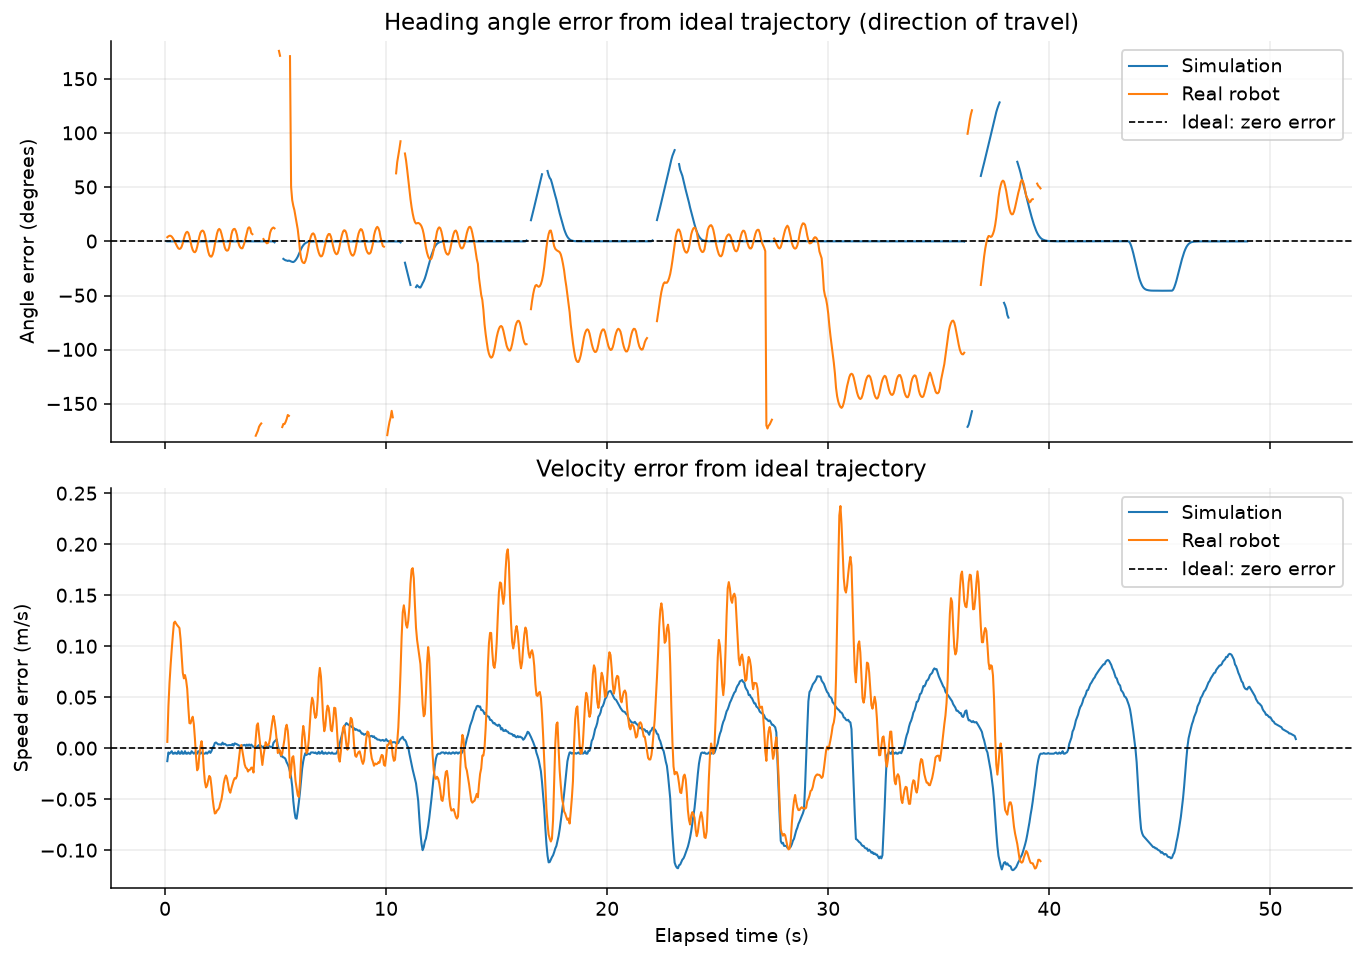

,sim,real
Direction-angle RMSE (degrees; moving windows),25.493,73.917
Speed RMSE (m/s),0.051,0.073
Valid angle windows,933.000,756.000
Total windows,1022.000,791.000


Ideal model completes in 48.98 s; time is not normalized to either recorded run.


In [7]:
# This cell is embedded in report.ipynb; the notebook remains standalone.
ERROR_GRID_S = 0.05
VELOCITY_WINDOW_S = 0.20
MIN_DIRECTION_SPEED = 0.005  # m/s


def wrap_angle(angle):
    return (np.asarray(angle) + np.pi) % (2 * np.pi) - np.pi


def ideal_rollout(points_cm, p, max_duration_s=600):
    """Ideal unicycle, held commands, exact circular-arc integration per step."""
    step = float(p['period_ms']) / 1000
    if step <= 0:
        raise ValueError('The ideal control period must be positive.')
    goals = np.asarray(points_cm[1:], dtype=float) / 100
    x = y = theta = t = 0.0
    target = 0
    history = [[t, x, y]]
    for _ in range(int(max_duration_s / step)):
        while target < len(goals) and np.linalg.norm(goals[target] - [x, y]) <= p['threshold']:
            target += 1
        if target == len(goals):
            return np.asarray(history)
        dx, dy = goals[target] - [x, y]
        dist = np.hypot(dx, dy)
        err = float(wrap_angle(np.arctan2(dy, dx) - theta))
        v = p['K_d'] * dist * np.cos(err)
        omega = p['K_angle'] * err + p['K_d'] * np.sin(err) * np.cos(err)
        scale = max(1.0, abs(v) / p['v_max'], abs(omega) / p['omega_max'])
        v, omega = v / scale, omega / scale
        # sinc gives the exact arc displacement, including the omega=0 limit.
        turn = omega * step
        travel = v * step * np.sinc(turn / (2 * np.pi))
        x += travel * np.cos(theta + turn / 2)
        y += travel * np.sin(theta + turn / 2)
        theta += turn
        t += step
        history.append([t, x, y])
    raise ValueError('Ideal reference did not complete within its time limit.')


def unique_positions(data):
    time_s = (data[:, 2] - data[0, 2]) / 1000
    times, inverse, counts = np.unique(time_s, return_inverse=True, return_counts=True)
    positions = np.column_stack([
        np.bincount(inverse, weights=data[:, axis] / 100) / counts for axis in [0, 1]])
    return times, positions


def window_velocity(times, positions, query, window_s):
    half = window_s / 2
    before = np.column_stack([np.interp(query - half, times, positions[:, axis]) for axis in [0, 1]])
    after = np.column_stack([np.interp(query + half, times, positions[:, axis]) for axis in [0, 1]])
    return (after - before) / window_s


def trajectory_errors(data, ideal):
    times, positions = unique_positions(data)
    half = VELOCITY_WINDOW_S / 2
    query = np.arange(half, times[-1] - half + 1e-9, ERROR_GRID_S)
    observed = window_velocity(times, positions, query, VELOCITY_WINDOW_S)
    reference = window_velocity(ideal[:, 0], ideal[:, 1:3], query, VELOCITY_WINDOW_S)
    speed, ideal_speed = np.linalg.norm(observed, axis=1), np.linalg.norm(reference, axis=1)
    valid = (speed >= MIN_DIRECTION_SPEED) & (ideal_speed >= MIN_DIRECTION_SPEED)
    angle = wrap_angle(np.arctan2(observed[:, 1], observed[:, 0]) -
                       np.arctan2(reference[:, 1], reference[:, 0]))
    angle[~valid] = np.nan
    return pd.DataFrame({'time_s': query, 'speed_m_s': speed,
                         'ideal_speed_m_s': ideal_speed,
                         'heading_error_deg': np.degrees(angle),
                         'velocity_error_m_s': speed - ideal_speed})


ideal_trajectory = ideal_rollout(WP, parameters['sim'])
error_series = {kind: trajectory_errors(data, ideal_trajectory) for kind, data in runs.items()}
error_metrics = {}
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, layout='constrained')
for kind, title, color in [('sim', 'Simulation', 'tab:blue'), ('real', 'Real robot', 'tab:orange')]:
    if kind not in error_series:
        continue
    values = error_series[kind]
    for ax, column in zip(axes, ['heading_error_deg', 'velocity_error_m_s']):
        # Break lines at the angle wrap boundary rather than drawing false jumps through zero.
        xx, yy = values['time_s'].to_numpy(), values[column].to_numpy()
        if column == 'heading_error_deg' and len(yy) > 1:
            breaks = np.flatnonzero(np.abs(np.diff(yy)) > 180) + 1
            xx, yy = np.insert(xx, breaks, np.nan), np.insert(yy, breaks, np.nan)
        ax.plot(xx, yy, color=color, lw=1.1, label=title)
    valid = values['heading_error_deg'].dropna().to_numpy()
    velocity = values['velocity_error_m_s'].to_numpy()
    error_metrics[kind] = {
        'angle_rmse_deg': float(np.sqrt(np.mean(valid**2))) if len(valid) else None,
        'velocity_rmse_m_s': float(np.sqrt(np.mean(velocity**2))) if len(velocity) else None,
        'angle_valid_windows': len(valid), 'total_windows': len(values)}
    values.to_csv(OUTPUT / f'{kind}_trajectory_errors.csv', index=False, na_rep='')

axes[0].set(title='Heading angle error from ideal trajectory (direction of travel)',
            ylabel='Angle error (degrees)', ylim=(-185, 185))
axes[1].set(title='Velocity error from ideal trajectory',
            ylabel='Speed error (m/s)', xlabel='Elapsed time (s)')
for ax in axes:
    ax.axhline(0, color='black', ls='--', lw=0.9, label='Ideal: zero error')
    ax.grid(alpha=0.25)
    ax.legend(loc='upper right')
fig.savefig(OUTPUT / 'heading_velocity_errors.png', dpi=180, bbox_inches='tight')
display(fig)
plt.close(fig)
show_table(pd.DataFrame(error_metrics).rename(index={
    'angle_rmse_deg': 'Direction-angle RMSE (degrees; moving windows)',
    'velocity_rmse_m_s': 'Speed RMSE (m/s)',
    'angle_valid_windows': 'Valid angle windows', 'total_windows': 'Total windows'}))
print(f'Ideal model completes in {ideal_trajectory[-1, 0]:.2f} s; '
      'time is not normalized to either recorded run.')


## Discussion

Both odometry logs document all nine waypoints reached in order within the 1.5 cm
acceptance radius; the largest minimum sampled waypoint misses are 1.48 cm in
simulation and 1.41 cm on the real robot, both at P9.
The simulator follows the planned strokes with small rounded corners, while the
real trace cuts the turn near P1, passes below P2 and overshoots above P4, with
visible oscillations along the straight strokes.
The real run takes 39.75 s versus 51.29 s in simulation, while its median logging
interval is 61 ms versus 20 ms, so its trajectory is sampled more sparsely.
With K_d = 0.8 and K_angle = 20, distance feedback reduces forward speed near each
goal and angle feedback steers toward it; the tolerance allows early switching
and corner rounding, although one pair of runs cannot isolate a gain's effect.
Against the ideal controller model, direction-angle RMSE is 25.49° in simulation
and 73.92° on the real robot, and speed RMSE is 0.051 and 0.073 m/s respectively;
these comparisons retain elapsed time, so different corner-arrival times also
contribute to the errors.
The angle is inferred from direction of travel and all recorded positions come
from encoder odometry, so these results demonstrate estimated path tracking
without independently establishing physical position or body-heading accuracy.


## Exports

Submit this notebook, both QRS programs and both raw logs.
The notebook saves plots, numerical results and unchanged course-named copies of
the logs under `nvm/report_outputs/`.
Trajectory coordinates are shown in cm; the error analysis converts them to
metres and timestamps to seconds.


In [8]:
exports = OUTPUT / 'submission_exports'
exports.mkdir(exist_ok=True)
for kind in ['sim', 'real']:
    source = Path(inputs[kind]['path'])
    destination = exports / f'odometry_data_{kind}.txt'
    if source.resolve() != destination.resolve():
        shutil.copyfile(source, destination)
    print(f'{kind}: exported unchanged raw log as {destination.name}')

results = {'input_units': {'position': 'cm', 'time': 'ms'}, 'waypoints_cm': WP.tolist(),
           'parameters': parameters, 'settings_sources': settings_sources,
           'inputs': inputs, 'statistics': statistics,
           'waypoint_miss_cm': {k: v.tolist() for k, v in misses.items()},
           'ordered_arrivals': arrivals, 'trajectory_error_metrics': error_metrics}
(OUTPUT / 'analysis_results.json').write_text(
    json.dumps(results, indent=2, allow_nan=False) + '\n', encoding='utf-8')
print('Saved trajectory plots, error series and analysis results.')


sim: exported unchanged raw log as odometry_data_sim.txt
real: exported unchanged raw log as odometry_data_real.txt
Saved trajectory plots, error series and analysis results.
